### Load the Data

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

# Change this to your actual dataset filename

df = pd.read_csv(r"C:\Users\Admin\Desktop\Training\Python Training\25-11-2026\data\clean_data.csv")

In [64]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,36,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0.0,8.0,0.5,1,6,4.0,0.0,5.0
1,36,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1.0,10.0,3.0,3,10,7.0,1.0,7.0
2,36,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0.0,7.0,3.0,3,0,0.0,0.0,0.0
3,36,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0.0,8.0,3.0,3,8,7.0,3.0,0.0
4,36,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1.0,6.0,3.0,3,2,2.0,2.0,2.0


### Summary Statistics

In [65]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate summary statistics
summary = numeric_df.agg([
    "mean",
    "median",
    "min",
    "max",
    "std"
])

print(summary)

              Age    DailyRate  DistanceFromHome  Education  EmployeeCount  \
mean    36.934014   802.485714          9.192517   2.912925            1.0   
median  36.000000   802.000000          7.000000   3.000000            1.0   
min     18.000000   102.000000          1.000000   1.000000            1.0   
max     60.000000  1499.000000         29.000000   5.000000            1.0   
std      9.006941   403.509100          8.106864   1.024165            0.0   

        EmployeeNumber  EnvironmentSatisfaction  HourlyRate  JobInvolvement  \
mean       1024.865306                 2.721769   65.891156        2.729932   
median     1020.500000                 3.000000   66.000000        3.000000   
min           1.000000                 1.000000   30.000000        1.000000   
max        2068.000000                 4.000000  100.000000        4.000000   
std         602.024335                 1.093082   20.329428        0.711561   

        JobLevel  ...  RelationshipSatisfaction  Standar

In [93]:
numeric_df.describe()


,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.934014,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.764966,11.103061,2.710884,2.761224,6.566667,4.207823,1.922789,4.107483
std,9.006941,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.782312,7.303828,1.037954,0.706476,4.906683,3.555335,2.478222,3.517487
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.500000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,2.500000,28.500000,4.500000,4.000000,18.000000,14.500000,7.500000,14.500000


### groupby().agg() function to compare groups

In [66]:
# Average salary by department
department_salary = df.groupby("Department")["MonthlyIncome"].agg(
    ["mean", "median", "min", "max"]
)

print(department_salary)


                               mean  median     min        max
Department                                                    
Human Resources         6188.186508  3886.0  1555.0  15569.375
Research & Development  5967.881443  4449.5  1009.0  15569.375
Sales                   6783.973112  5677.0  1052.0  15569.375


In [67]:
department_analysis = df.groupby("Department").agg({
    "Age": "mean",
    "MonthlyIncome": "mean",
    "YearsAtCompany": "mean",
    "EmployeeNumber": "count"
})

print(department_analysis)

                              Age  MonthlyIncome  YearsAtCompany  \
Department                                                         
Human Resources         37.809524    6188.186508        6.476190   
Research & Development  37.102062    5967.881443        6.477320   
Sales                   36.434783    6783.973112        6.778032   

                        EmployeeNumber  
Department                              
Human Resources                     63  
Research & Development             970  
Sales                              437  


In [68]:
gender_analysis = df.groupby("Gender").agg({
    "Age": "mean",
    "MonthlyIncome": "mean",
    "YearsAtCompany": "mean",
    "EmployeeNumber": "count"
})

print(gender_analysis)

              Age  MonthlyIncome  YearsAtCompany  EmployeeNumber
Gender                                                          
Female  37.265306    6411.250850        6.838435             588
Male    36.713152    6092.382653        6.385488             882


In [69]:
jobrole_analysis = df.groupby("JobRole").agg({
    "MonthlyIncome": ["mean", "median"],
    "Age": "mean",
    "YearsAtCompany": "mean",
    "EmployeeNumber": "count"
})

print(jobrole_analysis)


                          MonthlyIncome                   Age YearsAtCompany  \
                                   mean     median       mean           mean   
JobRole                                                                        
Healthcare Representative   7346.946565   6687.000  39.687023       7.709924   
Human Resources             4233.384615   3093.000  35.500000       5.153846   
Laboratory Technician       3277.389961   2950.000  34.335907       5.011583   
Manager                    15027.340686  15569.375  46.333333      11.392157   
Manufacturing Director      7258.758621   6397.000  38.413793       7.337931   
Research Director          13944.215625  15569.375  43.962500       9.575000   
Research Scientist          3254.582192   2910.000  34.311644       5.078767   
Sales Executive             6871.622699   6190.500  36.868098       7.223926   
Sales Representative        2657.036145   2610.000  30.168675       2.975904   

                          EmployeeNumbe

In [70]:

# Attrition count by department
department_attrition = pd.crosstab(
    df["Department"],
    df["Attrition"]
)

print(department_attrition)

Attrition                No  Yes
Department                      
Human Resources          51   12
Research & Development  836  134
Sales                   346   91


### Correlation Analysis

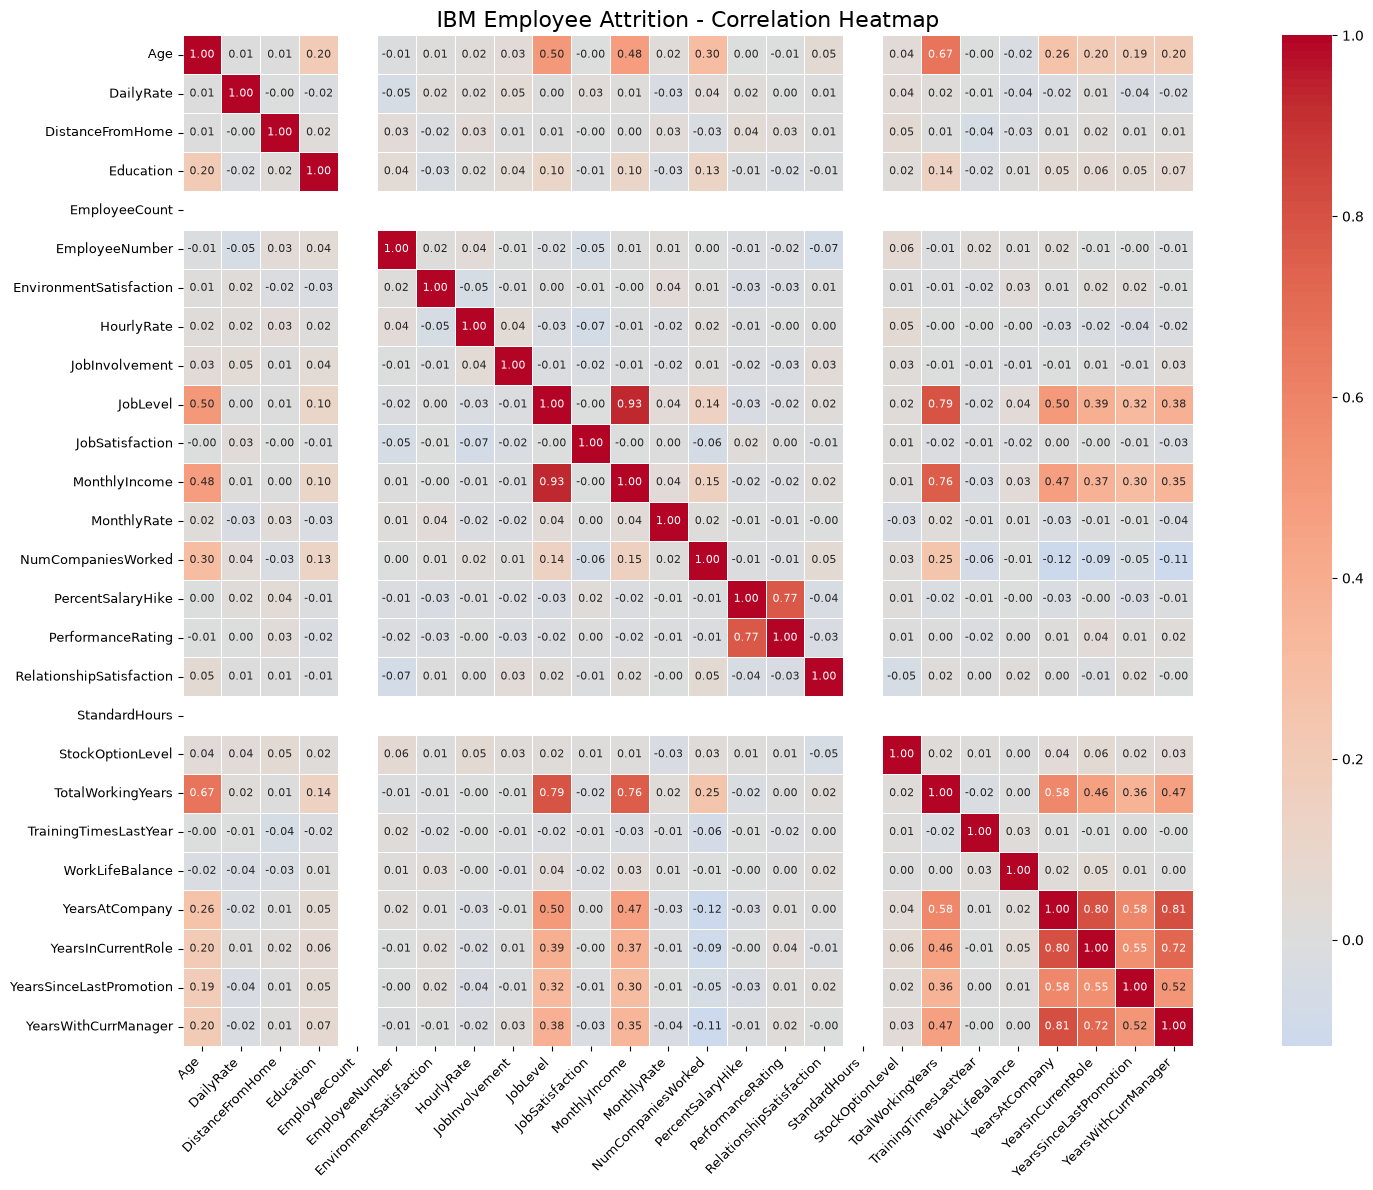

In [71]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation
correlation = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    annot_kws={"size": 8},
    center=0,
    square=True
)

plt.title("IBM Employee Attrition - Correlation Heatmap", fontsize=16)

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

In [72]:
# Get upper triangle of correlation matrix
corr_pairs = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
).stack()

# Get top 3 correlations
top_3 = corr_pairs.abs().sort_values(ascending=False).head(3)

print("Top 3 correlated relationships:")
print(top_3)

Top 3 correlated relationships:
JobLevel        MonthlyIncome           0.931136
YearsAtCompany  YearsWithCurrManager    0.813882
                YearsInCurrentRole      0.804181
dtype: float64


### Business Question

How much is the attrition percentage?

In [74]:
# Calculate attrition percentage

attrition_count = df["Attrition"].value_counts()

attrition_rate = (
    attrition_count["Yes"] / len(df)
) * 100

print("Total employees:", len(df))
print("Employees who left:", attrition_count["Yes"])
print("Attrition Rate:", round(attrition_rate, 2), "%")

Total employees: 1470
Employees who left: 237
Attrition Rate: 16.12 %


Which Department has highest Attrition?

In [80]:
dept_attrition = df.groupby("Department")["Attrition"].apply(
    lambda x: (x == "Yes").sum()
)

print(dept_attrition.sort_values(ascending=False))

Department
Research & Development    134
Sales                      91
Human Resources            12
Name: Attrition, dtype: int64


Which Age group we have Highest attrition?

In [83]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[18, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "Above 55"]
)

age_attrition = df.groupby("AgeGroup", observed=False)["Attrition"].apply(
    lambda x: (x == "Yes").sum()
)

print(age_attrition)

AgeGroup
18-25        39
26-35       112
36-45        49
46-55        25
Above 55      8
Name: Attrition, dtype: int64


Is Attrition because of Overtime?

In [84]:
# Attrition based on overtime

overtime_attrition = df.groupby("OverTime")["Attrition"].value_counts(
    normalize=True
).mul(100).round(2)

print(overtime_attrition)

OverTime  Attrition
No        No           89.56
          Yes          10.44
Yes       No           69.47
          Yes          30.53
Name: proportion, dtype: float64


Which Job role has highest monthly salary?

In [85]:
# Average monthly income by job role

job_salary = df.groupby("JobRole")["MonthlyIncome"].mean().sort_values(
    ascending=False
)

print(job_salary)

JobRole
Manager                      15027.340686
Research Director            13944.215625
Healthcare Representative     7346.946565
Manufacturing Director        7258.758621
Sales Executive               6871.622699
Human Resources               4233.384615
Laboratory Technician         3277.389961
Research Scientist            3254.582192
Sales Representative          2657.036145
Name: MonthlyIncome, dtype: float64


### Merge a second small table (for example department budget) 

In [86]:
# Create a second dataset

department_budget = pd.DataFrame({
    "Department": [
        "Sales",
        "Research & Development",
        "Human Resources"
    ],
    "Budget": [
        500000,
        1000000,
        300000
    ]
})

# Merge both datasets

merged_df = pd.merge(
    df,
    department_budget,
    on="Department",
    how="left"
)

print(merged_df.head())

   Age Attrition     BusinessTravel  DailyRate              Department  \
0   36       Yes      Travel_Rarely       1102                   Sales   
1   36        No  Travel_Frequently        279  Research & Development   
2   36       Yes      Travel_Rarely       1373  Research & Development   
3   36        No  Travel_Frequently       1392  Research & Development   
4   36        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  StockOptionLevel TotalWorkingYears  TrainingTimesLastYear  \
0  ..

In [91]:
# Save merged dataset
merged_df.to_csv("merged_employee_data.csv", index=False)

# Save pivot table
pivot_table.to_csv("department_attrition_pivot.csv")

print("EDA files saved successfully!")


EDA files saved successfully!


### Bonus Challenge

In [ ]:
# Department-wise employee attrition

pivot_table = pd.pivot_table(
    df,
    index="Department",
    columns="Attrition",
    values="EmployeeNumber",
    aggfunc="count",
    fill_value=0
)

print(pivot_table)

Attrition                No  Yes
Department                      
Human Resources          51   12
Research & Development  836  134
Sales                   346   91
